In [1]:
import sys
from pathlib import Path

# folders of the pipeline code, so that its modules can be imported from this notebook
CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

FEATURE_DIR = CODE_ROOT / "outputs" / "features" / "pyradiomics"   # features_<filter>.csv
CACHE_DIR = FEATURE_DIR / "task_features"                # one JSON file per task (lets a stopped run resume)


In [2]:
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
import radiomics

from scripts import list_case, task_name, largest_slice_index, load_reference_features, compare_features, summarize_comparison
from visualize import show_image_with_mask
from extraction import make_extractor, load_image_and_mask, preprocess, extract_features, run_all_tasks, save_feature_tables
from filter import (raw_image, binary_patterns, gradient_filter, log_filter, wavelet_filter, square_filter,
                           square_root_filter, logarithmic_filter, exponential_filter, gabor_filter, laws_filter)

radiomics.setVerbosity(logging.ERROR)    # hide PyRadiomics warnings
print("PyRadiomics", radiomics.__version__)

PyRadiomics 3.1.1.dev111+g8ed579383


In [3]:
SETTINGS = {
    # intensity normalization
    "normalize": True,
    "normalizeScale": 100,
    "removeOutliers": 3,
    "voxelArrayShift": 300,
    # geometry
    "resampledPixelSpacing": [1, 1, 1],
    "interpolator": "sitkBSpline",
    "padDistance": 10,
    "preCrop": True,
    # discretization
    "binCount": 32,
    # ROI checks
    "label": 1,
    "correctMask": False,
    "minimumROIDimensions": 3,
    "minimumROISize": 100,
    # texture options
    "distances": [1],
    "symmetricalGLCM": True,
    "weightingNorm": None,
    "force2D": False,
}

# Shape features are computed only once, with the raw image (they do not depend on intensities).
FEATURE_CLASSES = ["shape", "firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]

## Pre-processing before PyRadiomics

1. Registration
2. Bias field correction N4

In [4]:
REGISTRATION = True        # register channels 1-3 to channel 0
BIAS_CORRECTION = False    # N4 bias field correction

## Filters

One entry per output table `features_<name>.csv`: `name: (filter module, filter arguments)`.

In [5]:
FILTERS = {
    "raw_image":          (raw_image,          {}),
    "binary_patterns":    (binary_patterns,    {"lbp3DLevels": 2, "lbp3DIcosphereRadius": 1, "lbp3DIcosphereSubdivision": 1}),
    "gradient_filter":    (gradient_filter,    {"gradientUseSpacing": True}),
    "log_filter":         (log_filter,         {"sigma": [1.0, 2.0, 3.0, 4.0, 5.0]}),
    "wavelet_filter":     (wavelet_filter,     {"wavelet": "coif1", "level": 1, "start_level": 0}),
    "square_filter":      (square_filter,      {}),
    "square_root_filter": (square_root_filter, {}),
    "logarithmic_filter": (logarithmic_filter, {}),
    "exponential_filter": (exponential_filter, {}),
    "gabor_filter":       (gabor_filter,       {"gaborSigma": [2.0, 4.0],      # Gaussian envelope width (mm)
                                                "gaborLambda": [4.0, 8.0],     # wavelength (mm)
                                                "gaborGamma": 0.5,             # spatial aspect ratio
                                                "gaborOrientations": 8,        # number of angles averaged
                                                "gaborPlanes": ["axial"],
                                                "gaborTruncate": 3.0}),
    "laws_filter":        (laws_filter,        {"lawsKernels": ["L5E5E5", "E5E5E5", "L5S5S5", "S5S5S5", "E5W5R5", "R5R5R5"],
                                                "lawsRotationInvariant": True,
                                                "lawsPooling": "max",          # max | average
                                                "lawsEnergy": True,
                                                "lawsEnergyDistance": 7}),
}

## Task= Extract features for every case x breast side x MRI channel

In [6]:
CASES = list_case()
SIDES = ["L", "R"]
CHANNELS = [0, 1, 2, 3]
print("Cases:", CASES)
TASKS = [(case, side, channel) for case in CASES for side in SIDES for channel in CHANNELS]
print(len(CASES), "cases ->", len(TASKS), "tasks")
print("first task:", TASKS[0])

Cases: ['BreastMRI002', 'BreastMRI006', 'BreastMRI018', 'BreastMRI021', 'BreastMRI023']
5 cases -> 40 tasks
first task: ('BreastMRI002', 'L', 0)


## Create the PyRadiomics extractor

In [7]:
extractor = make_extractor(SETTINGS, FEATURE_CLASSES)
print("enabled feature classes:", list(extractor.enabledFeatures))

enabled feature classes: ['shape', 'firstorder', 'glcm', 'glrlm', 'glszm', 'gldm', 'ngtdm']


Check one task: load and pre-process

In [8]:
case, side, channel = TASKS[0]

image, mask = load_image_and_mask(case, side, channel, registration=REGISTRATION, bias_correction=BIAS_CORRECTION)
image, mask, bounding_box = preprocess(extractor, image, mask)

image_array = sitk.GetArrayFromImage(image)                        # [z, y, x]
mask_array = sitk.GetArrayFromImage(mask) == SETTINGS["label"]
spacing_zyx = np.array(image.GetSpacing())[::-1]

print("task:", task_name(case, side, channel))
print("size (x, y, z):", image.GetSize(), "| spacing:", image.GetSpacing(), "| ROI voxels:", int(mask_array.sum()))

task: BreastMRI002_L_ch0
size (x, y, z): (115, 165, 163) | spacing: (1.0, 1.0, 1.0) | ROI voxels: 236713


## Visualize the pre-processed image and ROI

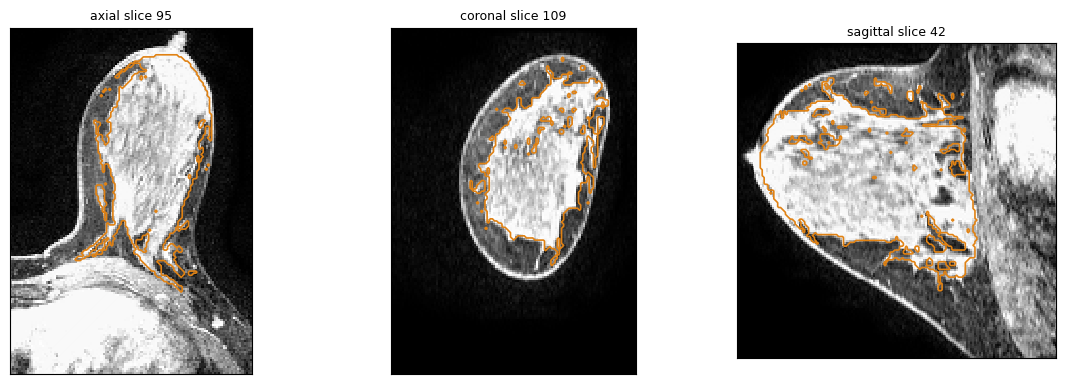

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, axis, plane in zip(axes, [0, 1, 2], ["axial", "coronal", "sagittal"]):
    index = largest_slice_index(mask_array, axis)
    show_image_with_mask(ax, image_array, mask_array, spacing_zyx, axis, index, title=f"{plane} slice {index}")
plt.show()

## Test one filter on this task

In [10]:
module, args = FILTERS["log_filter"]
features = extract_features(extractor, image, mask, bounding_box, module, args)

print(len(features), "features")
pd.Series(features).head(10)

465 features


log-sigma-1-0-mm-3D_firstorder_10Percentile            -5.039552e+01
log-sigma-1-0-mm-3D_firstorder_90Percentile             3.434675e+01
log-sigma-1-0-mm-3D_firstorder_Energy                   2.041298e+10
log-sigma-1-0-mm-3D_firstorder_Entropy                  3.762977e+00
log-sigma-1-0-mm-3D_firstorder_InterquartileRange       3.847295e+01
log-sigma-1-0-mm-3D_firstorder_Kurtosis                 3.779370e+00
log-sigma-1-0-mm-3D_firstorder_Maximum                  1.532516e+02
log-sigma-1-0-mm-3D_firstorder_MeanAbsoluteDeviation    2.548985e+01
log-sigma-1-0-mm-3D_firstorder_Mean                    -8.295261e+00
log-sigma-1-0-mm-3D_firstorder_Median                  -8.756018e+00
dtype: float64

In [11]:
run_all_tasks(extractor, TASKS, FILTERS, registration=REGISTRATION, bias_correction=BIAS_CORRECTION,
              cache_dir=CACHE_DIR, overwrite=False)

[1/40] BreastMRI002_L_ch0: done (raw_image, binary_patterns, gradient_filter, log_filter, wavelet_filter, square_filter, square_root_filter, logarithmic_filter, exponential_filter, gabor_filter, laws_filter)
[2/40] BreastMRI002_L_ch1: done (raw_image, binary_patterns, gradient_filter, log_filter, wavelet_filter, square_filter, square_root_filter, logarithmic_filter, exponential_filter, gabor_filter, laws_filter)
[3/40] BreastMRI002_L_ch2: done (raw_image, binary_patterns, gradient_filter, log_filter, wavelet_filter, square_filter, square_root_filter, logarithmic_filter, exponential_filter, gabor_filter, laws_filter)
[4/40] BreastMRI002_L_ch3: done (raw_image, binary_patterns, gradient_filter, log_filter, wavelet_filter, square_filter, square_root_filter, logarithmic_filter, exponential_filter, gabor_filter, laws_filter)
[5/40] BreastMRI002_R_ch0: done (raw_image, binary_patterns, gradient_filter, log_filter, wavelet_filter, square_filter, square_root_filter, logarithmic_filter, exponen

# Save one CSV per filter

In [12]:
tables = save_feature_tables(TASKS, list(FILTERS), CACHE_DIR, FEATURE_DIR)

pd.DataFrame({"rows": [len(t) for t in tables.values()],
              "feature columns": [max(t.shape[1] - 4, 0) for t in tables.values()]},   # minus case/side/channel/task
             index=[f"features_{name}.csv" for name in tables])

,rows,feature columns
features_raw_image.csv,40,107
features_binary_patterns.csv,40,279
features_gradient_filter.csv,40,93
features_log_filter.csv,40,465
features_wavelet_filter.csv,40,744
features_square_filter.csv,40,93
features_square_root_filter.csv,40,93
features_logarithmic_filter.csv,40,93
features_exponential_filter.csv,40,93
features_gabor_filter.csv,40,372
